# **AI Support Desk - Final Project**



*   **Course:** Python for Data and AI | ISCAP | Porto Executive Academy
*   **Name:** Luis Miguel Chaves Coimbra



In this project, I created an `AI Support Desk` to **analyse customer support tickets**, **clean** and **store** the data in SQLite, and **automatically classify tickets** into different categories using Gemini.

I compared Gemini's performance with a simple keyword-based classifier, evaluated the accuracy of both methods, and used Gemini to generate customer support replies.

Finally, I analysed the results using **charts**, rated the quality of the replies, and tested some additional features, such as predicting ticket priorities.

**Extra**: Some code references, such as iloc(), were included in the explanatory text to help readers understand what was being done and how certain results were obtained. However, the conclusions focus only on the main findings and insights, without including any code, so that people without programming knowledge can easily understand the results.

## Imports - Libraries and Modules

I used Pandas for data, matplotlib for creating charts, SQLITE through the support module, and Google's Gen AI library for live predictions. The functions and classes as intended are present in the **support_tools.ipynb** notebook, imported as tools.

In [ ]:
!pip install -q -U import-ipynb google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.63.0 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from google.colab import drive
import import_ipynb
import support_tools as tools
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import time

## **Part 1** - Load and explore the data

First, I load the store_tickets.csv file into a **DataFrame** and display the **first five rows** to understand its structure. Then, I check the **data types**, **number of rows and columns, missing values**, and the **different ways the categories are written.**

In [ ]:
from google.colab import drive

In [ ]:
drive.mount('/content/drive')
path = "/content/drive/MyDrive/Colab Notebooks/Final Project/Data/store_tickets.csv"
tickets = pd.read_csv(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
tickets.head(5)

,Ticket Number,Date,Customer,Email,Phone,Country,Order Number,Product Category,Order Value,Channel,Priority,Subject,Message,Category,Status,Rating,Internal Notes
0,T-1001,2026-01-01,Sofia Rodrigues,sofia.rodrigues31@example.com,+34 900 414 356,Spain,ORD-40037,Kitchen,154.46,Phone,Normal,Invoice needed,I need an invoice with my tax number for the b...,payment issue,Solved,3.0,NaN
1,T-1001,2026-01-01,Sofia Rodrigues,sofia.rodrigues31@example.com,+34 900 414 356,Spain,ORD-40037,Kitchen,154.46,Phone,Normal,Invoice needed,I need an invoice with my tax number for the b...,payment issue,Solved,3.0,NaN
2,T-1002,2026-01-02,Ana Rodrigues,ana.rodrigues91@example.com,+33 900 802 806,France,ORD-70919,Decor,80.96,Email,Normal,NaN,Please send me a return label for the vase.,Return request,Solved,3.0,NaN
3,T-1003,2026-01-02,Lucía Pereira,lucia.pereira63@example.com,+34 900 153 241,Spain,ORD-87465,Lighting,172.28,Phone,Normal,Discount code,My discount code was not applied when I paid f...,Payment issue,Solved,4.0,NaN
4,T-1004,2026-01-02,Hugo Rodrigues,hugo.rodrigues38@example.com,+39 900 786 103,Italy,ORD-48162,Furniture,400.88,Email,Low,Return item,I'd like to return the sofa. It doesn't match ...,Return request,Solved,5.0,NaN


In [ ]:
tickets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412 entries, 0 to 411
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Ticket Number     412 non-null    object 
 1   Date              412 non-null    object 
 2   Customer          412 non-null    object 
 3   Email             412 non-null    object 
 4   Phone             412 non-null    object 
 5   Country           412 non-null    object 
 6   Order Number      275 non-null    object 
 7   Product Category  356 non-null    object 
 8   Order Value       275 non-null    float64
 9   Channel           412 non-null    object 
 10  Priority          412 non-null    object 
 11  Subject           406 non-null    object 
 12  Message           408 non-null    object 
 13  Category          412 non-null    object 
 14  Status            412 non-null    object 
 15  Rating            209 non-null    float64
 16  Internal Notes    0 non-null      float64
dt

In [ ]:
# Size of dataframe - Rows and Columns
print(f"Number of rows: {tickets.shape[0]} and Number of Columns: {tickets.shape[1]}")

print("")

# Number of missing Values in each columns
print("Number of missing values in each columns:")
print(tickets.isnull().sum())

print("")

# Diferent ways category is written
print("Diferent ways category is written : ",tickets["Category"].unique())

Number of rows: 412 and Number of Columns: 17

Number of missing values in each columns:
Ticket Number         0
Date                  0
Customer              0
Email                 0
Phone                 0
Country               0
Order Number        137
Product Category     56
Order Value         137
Channel               0
Priority              0
Subject               6
Message               4
Category              0
Status                0
Rating              203
Internal Notes      412
dtype: int64

Diferent ways category is written :  ['payment issue' 'Return request' 'Payment issue' 'Delivery problem'
 'Return request ' 'Product question ' 'PRODUCT QUESTION' 'Account help'
 'product question' 'PAYMENT ISSUE' 'return request' 'DELIVERY PROBLEM'
 'account help' 'Product question' 'RETURN REQUEST' 'Delivery problem '
 'ACCOUNT HELP' 'delivery problem' 'Payment issue ' 'Account help ']


### **Part 1 Findings:**
After analysing the CSV file, it's possible to see that the dataset contains **412 rows and 17 columns.**

**Some columns contain missing values**, including "Order Number", "Product Category", "Order Value", "Rating" and "Internal Notes". The "Internal Notes" column has 412 missing values, meaning it is completely empty.

Looking at the "Category" column, we can see that **some categories are written differently**, even though they represent the same value. For example, "payment issue" and "Payment Issue".

I can also identify **unnecessary spaces in some values**, such as "Account help ".

To improve data quality and ensure consistency, these issues will be corrected during the data cleaning process.

## **Part 2** - Clean, and a few statistics

In **support_tools**, I created the **clean_tickets()** function to remove duplicate rows, personal information and tickets without messages.

First, I use **.str.strip()** to remove unnecessary spaces at the beginning and end of each message. Then, I use **!= ""** to remove empty messages and **.dropna()** to remove missing values **(NaN)**. This ensures that only tickets with valid messages remain.

Finally, I apply **.str.strip()** and **.str.lower()** to the **Category** column to remove unnecessary spaces and convert all categories to lowercase, making their values consistent.

In [ ]:
# Shape of dataset before and after applying clean_tickets from support_tools.ipynb
print(f"Number of tickets before cleaning: {tickets.shape[0]} | Number of columns: {tickets.shape[1]}")
tickets_cleaned = tools.clean_tickets(tickets)
print(f"Number of tickets after cleaning: {tickets_cleaned.shape[0]} | Number of columns: {tickets_cleaned.shape[1]}")

print("")

# Number of Categories and Tickers By Category
dif_cat = tickets_cleaned["Category"].nunique()
count_dif_cat = tickets_cleaned["Category"].value_counts()

print(f"Number of Categories: {dif_cat}")
print("")
print(f"Tickets By Category:")
print(count_dif_cat)

print("")

# Average rating per Category
print("Highest Rating:", tickets_cleaned["Rating"].max(), "| Lowest Rating:", tickets_cleaned["Rating"].min())
print("")
average_ratings_per_cat = tickets_cleaned.groupby("Category")["Rating"].mean().sort_values(ascending=False)
print("Average rating by category (Not Considering empty ratings):")
print(average_ratings_per_cat.round(2))


Number of tickets before cleaning: 412 | Number of columns: 17
Number of tickets after cleaning: 396 | Number of columns: 13

Number of Categories: 5

Tickets By Category:
Category
return request      98
delivery problem    90
product question    78
payment issue       77
account help        53
Name: count, dtype: int64

Highest Rating: 5.0 | Lowest Rating: 1.0

Average rating by category (Not Considering empty ratings):
Category
product question    4.12
account help        3.77
return request      3.07
payment issue       2.79
delivery problem    2.40
Name: Rating, dtype: float64


### **Part 2 Findings:**

After analysing the results, we can see that 16 rows were removed after applying the clean_tickets() function, along with four columns containing personal information or unnecessary data. The cleaned dataset now contains **396 rows and 13 columns.**

The cleaned dataset contains **5 categories**, with "return request" being the most common, containing 98 tickets.

Regarding the average rating by category, **"product question"** has the highest rating, with 4.12 out of 5, while **"delivery problem"** has the lowest, with 2.40 out of 5.

## **Part 3** - Charts of the data



In this part, I created some charts using `Matplotlib` to better understand the data in our dataset.

First, I created a **dictionary of colors** to use the same color for each category in the first two charts. This makes it easier to compare both charts without getting confused by different colors.

Then, I created **two bar charts to show the number of tickets per category and the average customer rating for each category**. I also added a red line showing the **overall average** in both charts, making it easier to see which categories are above or below the average.

After that, I created a **stacked bar chart** to see how the different ticket priorities are distributed across the channels.

Finally, I created a **line chart** to see how the number of orders changes over time. For this, I grouped the orders by month and counted the unique order numbers.

I also added the values to the charts to make it easier to analyze the results without having to estimate the numbers. I increased the limits of some graphs a little because some of the values were getting cut off.

The goal of this part is to visualize the data and better understand the differences between categories, priorities and orders over time.

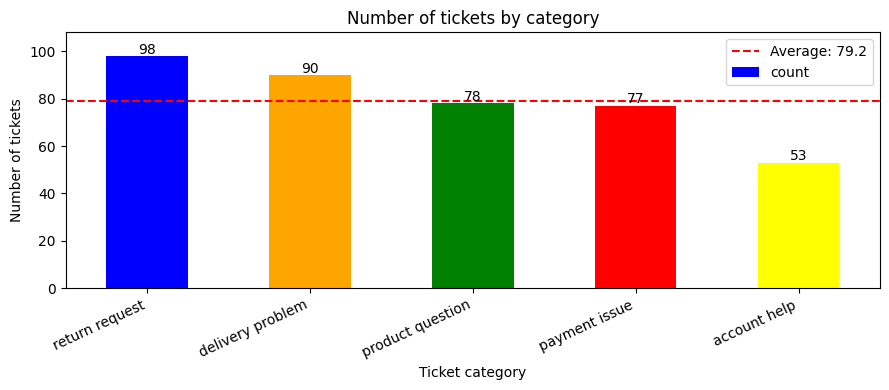

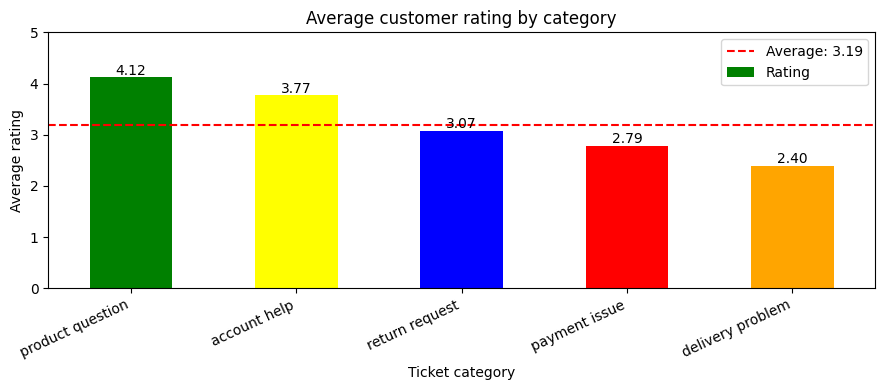

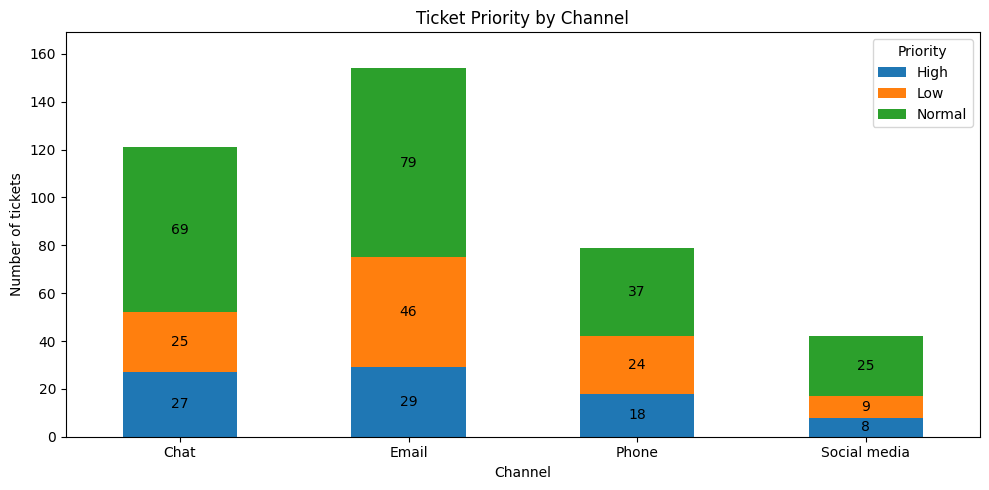

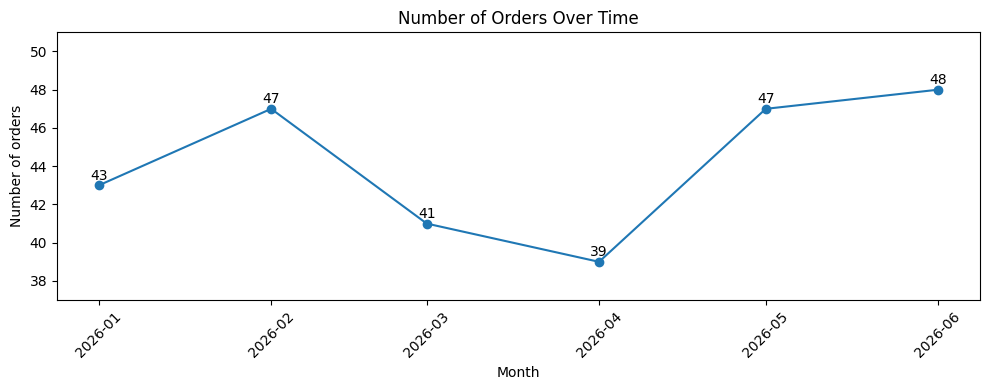

In [ ]:
# Number of tickets per category - Bar Chart

category_colors = {
    "return request": "blue",
    "delivery problem": "orange",
    "product question": "green",
    "payment issue": "red",
    "account help": "yellow"
}

average = count_dif_cat.mean()

plt.figure(figsize=(9, 4))

count_dif_cat.plot(
    kind="bar",
    color=[category_colors[cat] for cat in count_dif_cat.index]
)

# Add values above
for i, value in enumerate(count_dif_cat):
    plt.text(i, value + 1, str(value), ha="center")

plt.axhline(y=average, color="red", linestyle="--",label=f"Average: {average:.1f}")

plt.title("Number of tickets by category")
plt.xlabel("Ticket category")
plt.ylabel("Number of tickets")
plt.ylim(0, count_dif_cat.max() + 10)
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig("tickets_by_category.png", dpi=300, bbox_inches="tight")
plt.show()


#________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________

# Average Customer Rating by Category - Bar Chart

average = tickets_cleaned["Rating"].mean()

plt.figure(figsize=(9, 4))

average_ratings_per_cat.plot(
    kind="bar",
    color=[category_colors[cat] for cat in average_ratings_per_cat.index]
)

# Add values above
for i, value in enumerate(average_ratings_per_cat):
    plt.text(i, value + 0.05, f"{value:.2f}", ha="center")

plt.axhline(y=average, color="red", linestyle="--",label=f"Average: {average:.2f}")

plt.title("Average customer rating by category")
plt.xlabel("Ticket category")
plt.ylabel("Average rating")
plt.ylim(0, 5)
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig("average_rating_by_category.png", dpi=300, bbox_inches="tight")
plt.show()


#________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________

# Priority by Channel - Stacked Bar Chart

priority_channel = pd.crosstab(
    tickets_cleaned["Channel"],
    tickets_cleaned["Priority"]
)

ax = priority_channel.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

# Add values
for container in ax.containers:
    ax.bar_label(container, label_type="center")

plt.title("Ticket Priority by Channel")
plt.xlabel("Channel")
plt.ylabel("Number of tickets")
plt.ylim(0, priority_channel.sum(axis=1).max() + 15)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("priority_by_channel.png", dpi=300, bbox_inches="tight")
plt.show()


#________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________

# Number of Orders Over Time

tickets_cleaned["Date"] = pd.to_datetime(
    tickets_cleaned["Date"]
)

orders_per_month = (
    tickets_cleaned
    .dropna(subset=["Order Number", "Date"])
    .groupby(tickets_cleaned["Date"].dt.to_period("M"))["Order Number"]
    .nunique())

orders_per_month.index = orders_per_month.index.to_timestamp()

plt.figure(figsize=(10, 4))

plt.plot(
    orders_per_month.index,
    orders_per_month.values,
    marker="o")

# Add values above each point
for date, value in orders_per_month.items():
    plt.text(date, value + 0.3, str(value), ha="center")

plt.title("Number of Orders Over Time")
plt.xlabel("Month")
plt.ylabel("Number of orders")
plt.ylim(orders_per_month.min() - 2, orders_per_month.max() + 3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("orders_over_time.png", dpi=300, bbox_inches="tight")
plt.show()

### **Part 3 Findings:**

Looking at the `first chart`, we can see that return requests are the most common category, with **almost 100 tickets**, while account help has the **lowest** number, with around 53 tickets. The **average** is 79.2 tickets per category.

In the `second chart`, we can see that **product questions has the highest average customer rating**, with around 4.1, while **delivery problems has the lowest**, with around 2.4. The overall average is 3.19.

Then, I created a `stacked bar chart` to compare the priority of tickets by channel, to see if there is any relationship between the priority and the way customers contact support. Looking at the results, **there doesn't seem to be a clear relationship**, since the distribution of priorities is more or less similar across the different channels. We can also see that email is the most used channel.

Finally, I created a `line chart` to analyze the number of orders over time. We can see that March and April have the **lowest** number of orders, especially April with 39, while June has the **highest** with 48 orders. This difference could possibly be explained by **seasonality**, but we would need more data from other months and years to confirm this.


## **Part 4** - The TicketStore

We start by creating the `TicketStore class`, which manages our SQLite database. As required, we create two tables: **tickets**, where we store the cleaned data, and **triage**, where we save Gemini's predicted categories and generated replies for each ticket.

In [ ]:
# Database object
store_data = tools.TicketStore("tickets_store.db")

# Load the cleaned tickets with the load() method
store_data.load(tickets_cleaned)

# Sample tickets
sample_tickets = store_data.sample(20)
print("Sample size:", len(sample_tickets))

print("")
print("Frist Sampple as a tuple:")
print(sample_tickets[0])

Sample size: 20

Frist Sampple as a tuple:
('T-1001', 'I need an invoice with my tax number for the blender.', 'payment issue')


### **Part 4 Findings:**


We started by creating the `TicketStore` class in the support_tools.ipynb notebook, as requested in the exercise. This class includes methods, such as **load()**, which stores the cleaned tickets in the SQLite database, and **sample()**, which retrieves the first 20 tickets.

After loading the data, we select a **sample of 20 tickets** and displayed the total number of sampled tickets to confirm that the method worked correctly. We also **displayed the first ticket as a tuple**, containing its ticket number, message, and category.

## **Part 5** - The stand-in desk: your baseline

In order to do this part, I created a `SupportDesk` class in support_tools.ipynb in order to classify tickets using keywords.

I created a **dictionary** to connect keywords to the categories in the dataset.For example, if the message contains the word "return", it will be classified as "return request", and if it contains "invoice", it will be classified as "payment issue". If none of the keywords are found, the default category is "product question".

Then, I created the SupportDesk object and **gave it access to the database**.

Finally, I used a **list comprehension to compare the predicted categories with the correct ones**, getting True or False for each of the tickets. Finally, I used sum() to count the c**orrect predictions out of the total and calculate the accuracy.**

This will allow me to compare the results with Gemini later.

In [ ]:
# Creates a SupportDesk object using the database (store_data) I created earlier.
stand_in_desk = tools.SupportDesk(store_data)

sample_rows = stand_in_desk.triage(sample_tickets)

# List comprehension to check if each predicted category made is correct
correct_predictions = [
    true_category == category
    for number, true_category, category, reply in sample_rows
]

sum_correct_pred = sum(correct_predictions)
accuracy = sum_correct_pred / len(sample_rows)

print(f"Correctly classified: {sum_correct_pred} of {len(sample_rows)} tickets.")
print(f"Keyword classifier accuracy: {accuracy:.2f}")

Correctly classified: 12 of 20 tickets.
Keyword classifier accuracy: 0.60


### **Part 5 Findings:**

Looking at the results, we can see that the **keyword classifier correctly classified 12 out of 20 tickets**, giving an accuracy of 0.60 (60%).

This means that 8 tickets were classified incorrectly. This happens because our classifier only looks for the specific keywords mentioned above. If **we were to change the keywords, a different result could be expected.**

## **Part 6** - The Gemini desk

In this part, I created a `GeminiDesk class` in support_tools.ipynb to classify the tickets using Gemini instead of keywords and generate a reply for each customer.

Then, I created an **ask_gemini() method** based on Class 9 to send prompts to Gemini and return its answers.

I also changed the **classify()** and **draft_reply()** methods. The first asks Gemini to classify the message into one of our five categories, while the second generates a simple customer support reply. I asked Gemini to return only the category, because the **triage() method already has the ticket number.**

As requested , I added **time.sleep(5)** to wait five seconds after each API request. I also updated triage() with a save option, allowing us to save each result to SQLite as soon as the classification and reply are generated.

Finally, **I created the GeminiDesk object and used triage() to process the 20 tickets, save the results and display the ticket number with the predicted category.**

In [ ]:
from google.colab import userdata
from google import genai

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
MODEL = "gemini-3.8-flash"
FAST = {"thinking_config": {"thinking_level": "low"}}

client = genai.Client(api_key=GEMINI_API_KEY)

In [ ]:
# GeminiDesk object
gemini_desk = tools.GeminiDesk(store_data, client, MODEL, FAST)

# Classify the tickets, create replies and save the results to SQLite
gemini_rows = gemini_desk.triage(sample_tickets, save=True)

# Display the ticket number and predicted category
for number, true_category, category, reply in gemini_rows:
    print(f"The ticket number is {number} and the predicted category is {category}.")

The ticket number is T-1001 and the predicted category is payment issue.
The ticket number is T-1002 and the predicted category is return request.
The ticket number is T-1003 and the predicted category is payment issue.
The ticket number is T-1004 and the predicted category is return request.
The ticket number is T-1005 and the predicted category is delivery problem.
The ticket number is T-1006 and the predicted category is return request.
The ticket number is T-1007 and the predicted category is payment issue.
The ticket number is T-1008 and the predicted category is product question.
The ticket number is T-1009 and the predicted category is product question.
The ticket number is T-1010 and the predicted category is delivery problem.
The ticket number is T-1011 and the predicted category is delivery problem.
The ticket number is T-1012 and the predicted category is account help.
The ticket number is T-1013 and the predicted category is product question.
The ticket number is T-1014 and

In [ ]:
print(tickets_cleaned[tickets_cleaned["Ticket Number"] == "T-1020"])

Empty DataFrame
Columns: [Ticket Number, Date, Country, Order Number, Product Category, Order Value, Channel, Priority, Subject, Message, Category, Status, Rating]
Index: []


### **Part 6 Findings:**

Looking at the results, we can see that Gemini **successfully classified all 20 tickets into one of the five categories.**

I also noticed that ticket T-1020 was missing from the results. After checking the cleaned dataset, I found that this ticket was not there, which explains why the sample continued to T-1021.

The results were also saved to SQLite so we can use them later to calculate Gemini's accuracy and compare it with the keyword classifier.


## **Part 7** - Your feedback

In this part, I selected the **first five tickets** from the SQLite results using .iloc[:5].

Then, I used a for **loop** to display each customer's message and Gemini's reply. Using input(), I gave each reply a rating from 1 to 5 based on how useful and appropriate I thought it was.

The goal is to **evaluate the quality of Gemini's replies, not just whether it classified the tickets correctly.**

In [ ]:
# Get the results from SQLite

table = store_data.results()
first_five = table.iloc[:5]
display(first_five)


# Then we will use Input to give ratings
print("")
for index, row in first_five.iterrows():
    print("Ticket:", row["ticket_number"])
    print("Message:", row["message"])
    print("Gemini Reply:", row["ai_reply"])

    rating = int(input("Your rating (1-5): "))
    print()

,ticket_number,message,true_category,ai_category,ai_category_again,ai_reply,rating
0,T-1001,I need an invoice with my tax number for the b...,payment issue,payment issue,None,"Hi [Customer Name],\n\nI would be happy to hel...",None
1,T-1002,Please send me a return label for the vase.,return request,return request,None,"Hi [Customer Name],\n\nI’ve attached your prep...",None
2,T-1003,My discount code was not applied when I paid f...,payment issue,payment issue,None,"Hi [Customer Name],\n\nI’m sorry to hear your ...",None
3,T-1004,I'd like to return the sofa. It doesn't match ...,return request,return request,None,"Hi [Customer Name],\n\nI’m so sorry to hear th...",None
4,T-1005,My rug was supposed to arrive 6 days ago and I...,delivery problem,delivery problem,None,"Hi [Customer Name],\n\nI’m so sorry for the de...",None



Ticket: T-1001
Message: I need an invoice with my tax number for the blender.
Gemini Reply: Hi [Customer Name],

I would be happy to help you with that! 

Could you please reply with your **order number**, **tax ID/number**, and the **billing name and address** you’d like on the invoice? 

Once I have those details, I’ll update the invoice and email it right over to you.

Best regards,  
[Your Name / Company Name]
Your rating (1-5): 3

Ticket: T-1002
Message: Please send me a return label for the vase.
Gemini Reply: Hi [Customer Name],

I’ve attached your prepaid return shipping label to this email. Just print it out, attach it to your package, and drop it off at the nearest [Carrier Name, e.g., UPS/USPS]. 

Please let us know if you need any further assistance!

Best regards,  
[Your Name/Company Name]
Your rating (1-5): 2

Ticket: T-1003
Message: My discount code was not applied when I paid for the LED strip.
Gemini Reply: Hi [Customer Name],

I’m sorry to hear your discount code wa

In [ ]:
# My ratings for the first 5 tickets
ratings = [3, 2, 3, 3, 4]

# Save ratings
for ticket, rating in zip(sample_tickets[:5], ratings):
    store_data._cursor.execute(
        "UPDATE triage SET rating = ? WHERE ticket_number = ?",
        (rating, ticket[0]))


store_data._connection.commit()

# Check the saved ratings
display(store_data.results()[["ticket_number", "rating"]].head(5))

,ticket_number,rating
0,T-1001,3.0
1,T-1002,2.0
2,T-1003,3.0
3,T-1004,3.0
4,T-1005,4.0


### **Part 7 Findings:**

Analyzing the 5 results , i gave the ratings 3,2,3,3 and 4 ( **average of 3/5** ).

Overall, Gemini's response **understood the customer's problem and generated simple and polite replies**. **However**, there's some issues that we need to take into account.

For example, in ticket T-1002, Gemini said that a return label was attached, even though no attachment was actually implemented. It also mentioned refunds and we dont know the refund policy.

I also noticed some placeholders like [Customer Name], meaning that some editing is needed before sending , because in previous steps we removed Customer Name.

The best reply was the last one ( T-1005 ), with a rating of 4/5, because it **asked for the information needed to investigate the problem,** contributing to investigating the problem.

Overall, i think that Gemini was useful for creating draft replies, but **human review is still necessary** to make sure that the information is correctly handled.

Extra: After generating the Gemini predictions and replies, I kept the existing results in SQLite to avoid different responses. I then used SQL UPDATE to save my five feedback ratings without repeating the Gemini requests.


## **Part 8** - Evaluate the AI

In this part, I wanted to evaluate how well Gemini performed compared to the stand-in classifier from Part 5. **First**, I used the results saved in SQLite to compare Gemini's predicted categories with the real categories and calculate the **overall accuracy, accuracy per category and number of mistakes.**

Then, I tested Gemini's consistency by asking it to **classify the first 10 tickets again**. I stored the **new predictions in a DataFrame** and compared them with the original ones to see how many matched.

Finally, I calculated the **average rating **from the five replies I evaluated in Part 7.

In [ ]:
# Gemini results from SQLite
table = store_data.results()

# Compare Gemini predictions with the real categories
table["is_correct"] = table["ai_category"] == table["true_category"]

display(table)

,ticket_number,message,true_category,ai_category,ai_category_again,ai_reply,rating,is_correct
0,T-1001,I need an invoice with my tax number for the b...,payment issue,payment issue,None,"Hi [Customer Name],\n\nI would be happy to hel...",3.0,True
1,T-1002,Please send me a return label for the vase.,return request,return request,None,"Hi [Customer Name],\n\nI’ve attached your prep...",2.0,True
2,T-1003,My discount code was not applied when I paid f...,payment issue,payment issue,None,"Hi [Customer Name],\n\nI’m sorry to hear your ...",3.0,True
3,T-1004,I'd like to return the sofa. It doesn't match ...,return request,return request,None,"Hi [Customer Name],\n\nI’m so sorry to hear th...",3.0,True
4,T-1005,My rug was supposed to arrive 6 days ago and I...,delivery problem,delivery problem,None,"Hi [Customer Name],\n\nI’m so sorry for the de...",4.0,True
5,T-1006,Can I exchange the plant pots for a different ...,return request,return request,None,"Hi [Customer Name],\n\nYes, absolutely! We’d b...",NaN,True
6,T-1007,My discount code was not applied when I paid f...,payment issue,payment issue,None,"Hi [Customer Name],\n\nI’m sorry to hear that ...",NaN,True
7,T-1008,When will the curtains be back in stock?,product question,product question,None,"Hi there,\n\nThanks for reaching out! We expec...",NaN,True
8,T-1009,"Does the knife block come assembled, or do I n...",product question,product question,None,"Hi [Customer Name],\n\nThe knife block comes f...",NaN,True
9,T-1010,Can I change the delivery date of my vase? I w...,delivery problem,delivery problem,None,"Hi [Customer Name],\n\nYes, you can certainly ...",NaN,True


In [ ]:
# Calculate accuracy
gemini_accuracy = table["is_correct"].mean()
print("Gemini accuracy:", gemini_accuracy)

print("")
# Accuracy by category
accuracy_by_category = table.groupby("true_category")["is_correct"].mean()
print(accuracy_by_category)

print("")
# Incorrect Predictions
mistakes = table[table["is_correct"] == False]
print("Number of mistakes:", len(mistakes))

Gemini accuracy: 1.0

true_category
account help        1.0
delivery problem    1.0
payment issue       1.0
product question    1.0
return request      1.0
Name: is_correct, dtype: float64

Number of mistakes: 0


In [ ]:
### Now we ask again for Gemini to categorize the tickets

# First 10 tickets
table_2 = store_data.results()
first_ten_2 = table_2.iloc[:10]

comparison_results = []

# Ask Gemini to classify them again
for index, row in first_ten_2.iterrows():
    new_category = gemini_desk.classify(row["message"])

    comparison_results.append({
        "Ticket Number": row["ticket_number"],
        "Original Category": row["ai_category"],
        "New Category": new_category
    })


# Table format
comparison = pd.DataFrame(comparison_results)
display(comparison)

,Ticket Number,Original Category,New Category
0,T-1001,payment issue,payment issue
1,T-1002,return request,return request
2,T-1003,payment issue,payment issue
3,T-1004,return request,return request
4,T-1005,delivery problem,delivery problem
5,T-1006,return request,return request
6,T-1007,payment issue,payment issue
7,T-1008,product question,product question
8,T-1009,product question,product question
9,T-1010,delivery problem,delivery problem


In [ ]:
is_equal = (comparison["Original Category"] == comparison["New Category"]).mean()
print("Consistency:", round(is_equal * 100, 2), "%")

Consistency: 100.0 %


In [ ]:
print("Average rating:", store_data.results()["rating"].mean(), "/5")

Average rating: 3.0 /5


In [ ]:
#### All Information

print("Stand-in accuracy:", round(accuracy * 100, 2), "%")
print("Gemini accuracy:", round(gemini_accuracy * 100, 2), "%")
print("Consistency:", round(is_equal * 100, 2), "%")
print("Average rating:", store_data.results()["rating"].mean(), "/5")

Stand-in accuracy: 60.0 %
Gemini accuracy: 100.0 %
Consistency: 100.0 %
Average rating: 3.0 /5


### **Part 8 Findings:**

After evaluating the results, **Gemini achieved 100% accuracy**, correctly classifying all 20 tickets, while the **stand-in classifier only achieved 60% **accuracy. Gemini also had 100% accuracy in all five categories, meaning there were no incorrect predictions in this sample.

For the consistency test, I asked Gemini to classify the first 10 tickets again, and it returned exactly the same categories as before, giving a **consistency of 100%.**

However, the average rating I gave to the five generated replies was only 3/5. This shows that even though Gemini was very good at identifying the correct categories, its replies were not always reliable.

## **Part 9** - Charts of the AI's performance

In this part, I created three charts using Matplotlib to better visualize the results from the previous sections.

First, I created a **bar chart comparing the overall accuracy of the stand-in classifier and Gemini**. Then, I used a **heatmap** to **compare their accuracy across the five categories,** using colors from red to green to make the differences easier to understand.

Finally, I created a **bar chart showing the ratings I gave to Gemini's five replies,** including a line representing the average rating. The goal is to make it easier to compare the performance of both classifiers and understand how useful Gemini's replies were.

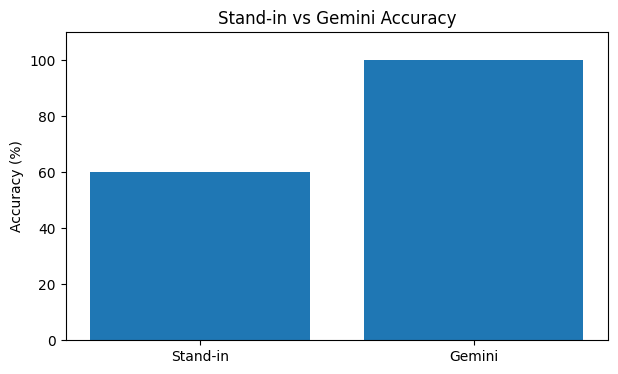

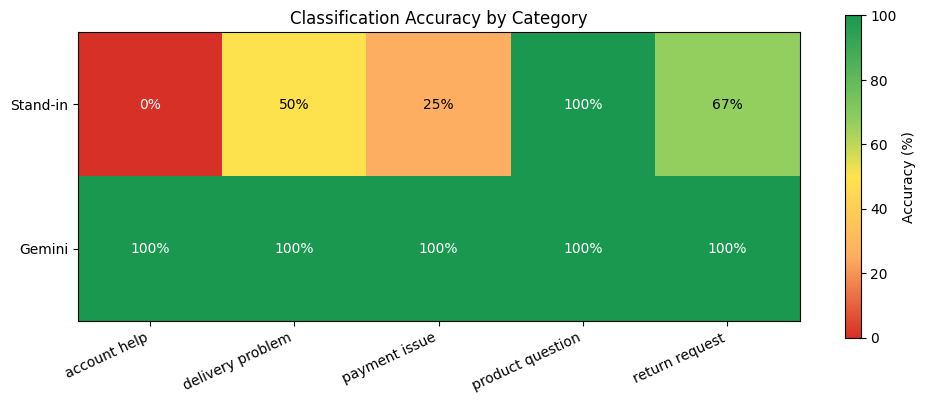

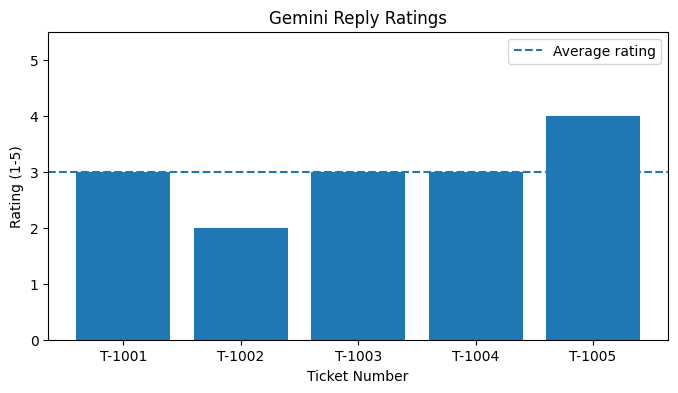

In [ ]:
# Compare accuracy
models = ["Stand-in", "Gemini"]
accuracies = [accuracy * 100, gemini_accuracy * 100]

plt.figure(figsize=(7, 4))
plt.bar(models, accuracies)
plt.title("Stand-in vs Gemini Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)
plt.savefig("stand_in_vs_gemini_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

#__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________

# Get the results from SQLite
table = store_data.results()

# Check if each classifier was correct
table["stand_in_correct"] = table["message"].apply(stand_in_desk.classify) == table["true_category"]
table["gemini_correct"] = table["ai_category"] == table["true_category"]

# Calculate accuracy by category
heatmap_data = table.groupby("true_category")[["stand_in_correct", "gemini_correct"]].mean() * 100
heatmap_data.columns = ["Stand-in", "Gemini"]
heatmap_data = heatmap_data.T

# Custom colors from red to green
accuracy_colors = LinearSegmentedColormap.from_list(
    "accuracy_colors",
    [
        (0.00, "#d73027"),  # Red
        (0.25, "#fdae61"),  # Orange
        (0.50, "#ffe34d"),  # Yellow
        (0.67, "#91cf60"),  # Light green
        (1.00, "#1a9850")   # Green
    ]
)

# Create heatmap
plt.figure(figsize=(10, 4))
plt.imshow(heatmap_data, cmap=accuracy_colors, vmin=0, vmax=100)
plt.colorbar(label="Accuracy (%)")

# Categories at the bottom, models on the left
plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns, rotation=25, ha="right")
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)

# Show percentages inside each cell
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.iloc[i, j]
        plt.text(j, i, f"{value:.0f}%", ha="center", va="center",
                 color="white" if value == 0 or value >= 85 else "black")

plt.title("Classification Accuracy by Category")
plt.tight_layout()

plt.savefig("classification_accuracy_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


#____________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________


# Get the ratings from SQLite
ratings_table = store_data.results().dropna(subset=["rating"])

plt.figure(figsize=(8, 4))
plt.bar(ratings_table["ticket_number"], ratings_table["rating"])
plt.axhline(ratings_table["rating"].mean(), linestyle="--", label="Average rating")
plt.title("Gemini Reply Ratings")
plt.xlabel("Ticket Number")
plt.ylabel("Rating (1-5)")
plt.ylim(0, 5.5)
plt.legend()
plt.savefig("gemini_reply_ratings.png", dpi=300, bbox_inches="tight")
plt.show()

### **Part 9 Findings:**

Looking at the first chart, we can clearly see that **Gemini performed better than the stand-in classifier,** achieving 100% accuracy compared to 60%.

The heatmap gives a more detailed comparison. Gemini achieved 100% accuracy in all five categories, while the stand-in classifier had very different results depending on the category. For example, it achieved 100% in product questions but 0% in account help. This shows that the **keyword-based approach works better for some categories than others.**

The last chart shows that Gemini's replies received ratings between 2 and 4, with an average of 3/5. **Even though Gemini correctly classified every ticket, the quality of its replies was not always as good.**

##**Part 10** — Results & conclusions

After cleaning the dataset, I ended up with 396 tickets divided into five categories. The most common category was return request, with 98 tickets, while delivery problem had the lowest average customer rating (2.40/5). This shows that returns are a frequent reason for contacting support, but delivery problems seem to cause more dissatisfaction among customers.

Regarding the AI, Gemini achieved 100% accuracy on the 20 tickets tested, compared to 60% for the stand-in classifier. Gemini also showed 100% consistency when classifying 10 tickets again. **There were no classification mistakes**, although the **sample was quite small**. The stand-in classifier struggled because it only searched for a few specific keywords, which didn't always represent the customer's problem. However, Gemini wasn't perfect when generating replies. **The five replies received an average rating of 3/5, mainly because some included information that wasn't confirmed, such as refunds.**

There's some improvments i would make like adding `clearer instructions` to the AI, in order to generate better results regarding the situation. Example: A company that doesn't take refunds should tell the AI that, so it doesn't make false promises to the client.

Another important one, would be to `use more data` in order to see if the accuray remains high. Overall this project can be useful to automate customer suport tasks, but human hand is always going to be necessary.

## 🌟 Stretch Goals — a bonus

## **A )** "Ask Gemini for the ticket's priority too, and evaluate it against Priority."

In this bonus section, I wanted to see if Gemini could also **predict the priority of customer support ticket**s, instead of only classifying their categories.

First, I checked the available priorities in the dataset, which were Low, Normal and High. Then, I used the same 20 tickets from the previous sections and asked Gemini to predict the priority of each one.

Finally, **I compared Gemini's predictions with the real priorities** in the dataset, calculated the accuracy and displayed the incorrect predictions to understand where Gemini struggled.

In [19]:
tickets_cleaned_bonus=tickets_cleaned.copy()

tickets_cleaned_bonus

,Ticket Number,Date,Country,Order Number,Product Category,Order Value,Channel,Priority,Subject,Message,Category,Status,Rating
0,T-1001,2026-01-01,Spain,ORD-40037,Kitchen,154.46,Phone,Normal,Invoice needed,I need an invoice with my tax number for the b...,payment issue,Solved,3.0
2,T-1002,2026-01-02,France,ORD-70919,Decor,80.96,Email,Normal,NaN,Please send me a return label for the vase.,return request,Solved,3.0
3,T-1003,2026-01-02,Spain,ORD-87465,Lighting,172.28,Phone,Normal,Discount code,My discount code was not applied when I paid f...,payment issue,Solved,4.0
4,T-1004,2026-01-02,Italy,ORD-48162,Furniture,400.88,Email,Low,Return item,I'd like to return the sofa. It doesn't match ...,return request,Solved,5.0
5,T-1005,2026-01-02,Spain,ORD-85573,Decor,160.97,Chat,High,Order not arrived,My rug was supposed to arrive 6 days ago and I...,delivery problem,Solved,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
407,T-1396,2026-06-28,Portugal,ORD-28899,Garden,299.48,Chat,High,Wrong amount,"I paid 299.48 euros for the parasol, but it wa...",payment issue,Waiting,NaN
408,T-1397,2026-06-29,France,NaN,Kitchen,NaN,Social media,Normal,Stock question,When will the frying pan set be back in stock?,product question,Solved,3.0
409,T-1398,2026-06-29,Spain,NaN,Furniture,NaN,Social media,Normal,Size question,What are the exact measurements of the sofa?,product question,Waiting,NaN
410,T-1399,2026-06-29,France,ORD-46448,Furniture,242.31,Social media,Normal,Invoice needed,I need an invoice with my tax number for the o...,payment issue,Open,NaN


In [20]:
print(tickets_cleaned_bonus["Priority"].value_counts())

Priority
Normal    210
Low       104
High       82
Name: count, dtype: int64


In [22]:
# Predict each ticket
# Create the GeminiDesk object
gemini_desk = tools.GeminiDesk(store_data, client, MODEL, FAST)

priority_results = []

for number, message, category in sample_tickets:

    real_priority = tickets_cleaned.loc[
        tickets_cleaned["Ticket Number"] == number, "Priority"
    ].iloc[0]

    prompt = (
        f"Classify the priority of this ticket "
        f"{', '.join(tickets_cleaned['Priority'].dropna().unique())}. "
        f"Only return the priority. Message: {message}"
    )

    ai_priority = gemini_desk.ask_gemini(prompt).lower().strip()

    priority_results.append({
        "Ticket Number": number,
        "Real Priority": real_priority.lower(),
        "AI Priority Prediction": ai_priority
    })

In [23]:
# Create table
priority_table = pd.DataFrame(priority_results)
display(priority_table)

# Calculate accuracy
priority_table["is_correct"] = priority_table["Real Priority"] == priority_table["AI Priority Prediction"]

print("")
priority_accuracy = priority_table["is_correct"].mean()
print("Priority accuracy:", round(priority_accuracy * 100, 2), "%")
print("")

# Show mistakes
mistakes = priority_table[priority_table["is_correct"] == False]
display(mistakes)

,Ticket Number,Real Priority,AI Priority Prediction
0,T-1001,normal,low
1,T-1002,normal,normal
2,T-1003,normal,normal
3,T-1004,low,normal
4,T-1005,high,high
5,T-1006,normal,low
6,T-1007,high,normal
7,T-1008,normal,low
8,T-1009,low,low
9,T-1010,normal,normal



Priority accuracy: 40.0 %



,Ticket Number,Real Priority,AI Priority Prediction,is_correct
0,T-1001,normal,low,False
3,T-1004,low,normal,False
5,T-1006,normal,low,False
6,T-1007,high,normal,False
7,T-1008,normal,low,False
12,T-1013,normal,low,False
13,T-1014,low,normal,False
14,T-1015,low,normal,False
15,T-1016,low,normal,False
16,T-1017,normal,low,False


After comparing the results, **Gemini achieved only 40% accuracy**, correctly predicting the priority of 8 out of 20 tickets. This was much lower than the 100% accuracy it achieved when classifying ticket categories.

Looking at the mistakes, I noticed that Gemini **sometimes considered tickets less or more urgent than their real priority.** For example, ticket T-1001 had a Normal priority, but Gemini classified it as Low. On the other hand, ticket T-1021 had a Normal priority, but Gemini classified it as High.

I think this happened because predicting **priority is more subjective than identifying the category**. Gemini only received the customer's message, without any clear rules explaining what makes a ticket Low, Normal or High priority. In a real support system, priority might also depend on other information that isn't mentioned in the message.


`Future improvement:` Give Ai more context on what is a high/medium/low priority ticket

## **B )** "Add one example ticket per category to the prompt, and measure whether the accuracy improves."

In this part, I wanted to see **if giving Gemini some examples would help improve its priority predictions.**

First, **I selected one ticket for each priority level** (Low, Normal and High) from the dataset, making sure `these tickets were not included in the original 20 samples`. This way, Gemini could learn from different examples without using the same tickets that I would later evaluate.

Then, **I added these three examples to the prompt** and asked Gemini to classify the same 20 tickets again. Finally, I compared the new accuracy with the original results to see if the examples made any difference.

In [43]:
tickets_cleaned_bonus

,Ticket Number,Date,Country,Order Number,Product Category,Order Value,Channel,Priority,Subject,Message,Category,Status,Rating
0,T-1001,2026-01-01,Spain,ORD-40037,Kitchen,154.46,Phone,Normal,Invoice needed,I need an invoice with my tax number for the b...,payment issue,Solved,3.0
2,T-1002,2026-01-02,France,ORD-70919,Decor,80.96,Email,Normal,NaN,Please send me a return label for the vase.,return request,Solved,3.0
3,T-1003,2026-01-02,Spain,ORD-87465,Lighting,172.28,Phone,Normal,Discount code,My discount code was not applied when I paid f...,payment issue,Solved,4.0
4,T-1004,2026-01-02,Italy,ORD-48162,Furniture,400.88,Email,Low,Return item,I'd like to return the sofa. It doesn't match ...,return request,Solved,5.0
5,T-1005,2026-01-02,Spain,ORD-85573,Decor,160.97,Chat,High,Order not arrived,My rug was supposed to arrive 6 days ago and I...,delivery problem,Solved,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
407,T-1396,2026-06-28,Portugal,ORD-28899,Garden,299.48,Chat,High,Wrong amount,"I paid 299.48 euros for the parasol, but it wa...",payment issue,Waiting,NaN
408,T-1397,2026-06-29,France,NaN,Kitchen,NaN,Social media,Normal,Stock question,When will the frying pan set be back in stock?,product question,Solved,3.0
409,T-1398,2026-06-29,Spain,NaN,Furniture,NaN,Social media,Normal,Size question,What are the exact measurements of the sofa?,product question,Waiting,NaN
410,T-1399,2026-06-29,France,ORD-46448,Furniture,242.31,Social media,Normal,Invoice needed,I need an invoice with my tax number for the o...,payment issue,Open,NaN


In [44]:
# Exclude the 20 test tickets
other_tickets = tickets_cleaned_bonus[
    ~tickets_cleaned_bonus["Ticket Number"].isin(priority_table["Ticket Number"])
]
other_tickets.shape

(376, 13)

In [45]:
other_tickets_low=other_tickets[other_tickets["Priority"]=='Low']
print("Low Example")
other_tickets_low["Message"].head(1)

Low Example


,Message
22,The LED strip is too big for my room. How do I...


In [46]:
other_tickets_med=other_tickets[other_tickets["Priority"]=='Normal']
print("Medium Example")
other_tickets_med["Message"].head(1)



Medium Example


,Message
24,"I can't log in, so I can't check where my lawn..."


In [47]:
other_tickets_hig=other_tickets[other_tickets["Priority"]=='High']
print("High Example")
other_tickets_hig["Message"].head(1)

High Example


,Message
23,"The desk lamp was delivered today, but the box..."


In [48]:
low_example = other_tickets_low["Message"].iloc[0]
normal_example = other_tickets_med["Message"].iloc[0]
high_example = other_tickets_hig["Message"].iloc[0]

In [49]:
# Predict each ticket
gemini_desk = tools.GeminiDesk(store_data, client, MODEL, FAST)

priority_results_examples = []

for number, message, category in sample_tickets:

    real_priority = tickets_cleaned.loc[
        tickets_cleaned["Ticket Number"] == number, "Priority"
    ].iloc[0]

    prompt = (
        f"Classify the priority of this support ticket as Low, Normal, or High.\n\n"

        f"Here are some examples:\n"
        f"Message: {low_example}\nPriority: Low\n\n"
        f"Message: {normal_example}\nPriority: Normal\n\n"
        f"Message: {high_example}\nPriority: High\n\n"

        f"Now classify this ticket:\n"
        f"Message: {message}\n\n"
        f"Only return the priority."
    )

    ai_priority = gemini_desk.ask_gemini(prompt).lower().strip()

    priority_results_examples.append({
        "Ticket Number": number,
        "Real Priority": real_priority.lower(),
        "AI Priority Prediction": ai_priority
    })

In [50]:
priority_df_examples = pd.DataFrame(priority_results_examples)

priority_df_examples["is_correct"] = (
    priority_df_examples["Real Priority"] ==
    priority_df_examples["AI Priority Prediction"])

accuracy_examples = priority_df_examples["is_correct"].mean() * 100

print(f"Original accuracy: 40.0%")
print(f"Accuracy with examples: {accuracy_examples:.1f}%")

Original accuracy: 40.0%
Accuracy with examples: 40.0%


After adding one example for each priority level, **Gemini achieved 40% accuracy, exactly the same as before**. This means it correctly predicted 8 out of 20 tickets, so there was no improvement in the overall accuracy.

Priority can be difficult to predict because it depends on how urgent a situation is, and the customer's message might not provide all the necessary information.

## **C )** "Ask Gemini whether each drafted reply promises something it shouldn't, and count how often."

In this part, I wanted to check `if Gemini's generated replies were making promises that hadn't been confirmed, such as refunds, return labels or pickups.`

Instead of using the original 20 tickets,** I decided to use 50 tickets from the cleaned dataset to have a larger sample** and get a better understanding of how often this happens.

For each ticket, I asked Gemini to **generate a customer support reply and then used Gemini again to check if that reply contained any unconfirmed promises**, giving a short explanation.

I **saved the results in a separate SQLite table** called promises_new_data, without changing the previous results. Finally, I calculated how many replies were flagged and the percentage of the total.

In [62]:
# Create a separate SQLite table for 50 sample
store_data._cursor.execute("""
    CREATE TABLE IF NOT EXISTS promises_new_data (
        ticket_number TEXT PRIMARY KEY,
        message TEXT,
        ai_reply TEXT,
        ai_review TEXT,
        has_promise INTEGER
    )
""")

store_data._connection.commit()

# Take 50 tickets from the cleaned DataFrame
bonus_c_tickets = tickets_cleaned.head(50)

for index, row in bonus_c_tickets.iterrows():

    number = row["Ticket Number"]
    message = row["Message"]

    # Skip tickets already saved
    store_data._cursor.execute(
        "SELECT ticket_number FROM promises_new_data WHERE ticket_number = ?",
        (number,)
    )

    if store_data._cursor.fetchone():
        continue

    # Generate Gemini's reply
    reply = gemini_desk.draft_reply(message)

    # Prompt
    prompt = (
        "Check if this customer support reply makes any promises "
        "that have not been confirmed yet, such as refunds, return labels, "
        "arranging pickups, or other unconfirmed promises. "
        "Answer Yes or No, followed by a short explanation. "
        "Start your answer with Yes or No, without any markdown formatting.\n\n"
        f"Customer message: {message}\n"
        f"AI reply: {reply}"
    )

    ai_check = gemini_desk.ask_gemini(prompt).strip()

    # Correctly identify Yes or No
    has_promise = int(
        ai_check.lstrip("* \n\t").lower().startswith("yes")
    )

    # Save results in the new SQLite table
    store_data._cursor.execute("""
        INSERT INTO promises_new_data
        (ticket_number, message, ai_reply, ai_review, has_promise)
        VALUES (?, ?, ?, ?, ?)
    """, (
        number,
        message,
        reply,
        ai_check,
        has_promise
    ))

    store_data._connection.commit()

In [63]:
# Display results
promise_table = pd.read_sql_query(
    "SELECT * FROM promises_new_data",
    store_data._connection
)

display(promise_table)

,ticket_number,message,ai_reply,ai_review,has_promise
0,T-1001,I need an invoice with my tax number for the b...,"Hi [Customer Name],\n\nI would be happy to hel...","Yes, the reply promises to generate and send a...",1
1,T-1002,Please send me a return label for the vase.,"Hi [Customer Name],\n\nI would be happy to hel...","Yes, the reply promises to generate and email ...",1
2,T-1003,My discount code was not applied when I paid f...,"Hi [Name],\n\nI'm sorry to hear your discount ...","Yes, the reply explicitly promises to ""refund ...",1
3,T-1004,I'd like to return the sofa. It doesn't match ...,"Hello,\n\nI'm very sorry to hear that the sofa...","Yes, the reply explicitly promises to ""arrange...",1
4,T-1005,My rug was supposed to arrive 6 days ago and I...,"Hi there,\n\nI am so sorry for the delay and t...","No, the reply does not make any unconfirmed pr...",0
5,T-1006,Can I exchange the plant pots for a different ...,"Hi [Name],\n\nYes, absolutely! We'd be happy t...",Yes. The reply confirms that the customer can ...,1
6,T-1007,My discount code was not applied when I paid f...,"Hi [Customer Name],\n\nI’m sorry to hear your ...","Yes. The reply promises to ""issue a refund for...",1
7,T-1008,When will the curtains be back in stock?,"Hi there,\n\nThanks for reaching out! We expec...","No, the reply only provides an expected timefr...",0
8,T-1009,"Does the knife block come assembled, or do I n...","Hi there,\n\nThe knife block comes fully assem...",No. The reply simply answers a factual product...,0
9,T-1010,Can I change the delivery date of my vase? I w...,"Hi [Customer Name],\n\nYes, you can! Please re...",Yes. The reply confirms that the delivery date...,1


In [64]:
# Count unconfirmed promises
total_promises = promise_table["has_promise"].sum()

print("Total replies checked:", len(promise_table))
print("Replies with unconfirmed promises:", total_promises)
print("Percentage:", round(promise_table["has_promise"].mean() * 100, 2), "%")

# Display replies with unconfirmed promises
display(promise_table[promise_table["has_promise"] == 1])

Total replies checked: 50
Replies with unconfirmed promises: 27
Percentage: 54.0 %


,ticket_number,message,ai_reply,ai_review,has_promise
0,T-1001,I need an invoice with my tax number for the b...,"Hi [Customer Name],\n\nI would be happy to hel...","Yes, the reply promises to generate and send a...",1
1,T-1002,Please send me a return label for the vase.,"Hi [Customer Name],\n\nI would be happy to hel...","Yes, the reply promises to generate and email ...",1
2,T-1003,My discount code was not applied when I paid f...,"Hi [Name],\n\nI'm sorry to hear your discount ...","Yes, the reply explicitly promises to ""refund ...",1
3,T-1004,I'd like to return the sofa. It doesn't match ...,"Hello,\n\nI'm very sorry to hear that the sofa...","Yes, the reply explicitly promises to ""arrange...",1
5,T-1006,Can I exchange the plant pots for a different ...,"Hi [Name],\n\nYes, absolutely! We'd be happy t...",Yes. The reply confirms that the customer can ...,1
6,T-1007,My discount code was not applied when I paid f...,"Hi [Customer Name],\n\nI’m sorry to hear your ...","Yes. The reply promises to ""issue a refund for...",1
9,T-1010,Can I change the delivery date of my vase? I w...,"Hi [Customer Name],\n\nYes, you can! Please re...",Yes. The reply confirms that the delivery date...,1
10,T-1011,Only half of my order came. The parasol is mis...,"Hi [Customer Name],\n\nI’m so sorry to hear th...","Yes. The reply promises to ""make sure the rest...",1
13,T-1014,I changed my mind about the garden chairs. It'...,"Hi [Customer Name],\n\nNo problem at all! Sinc...",Yes. The reply prematurely confirms return eli...,1
14,T-1015,Please send me a return label for the dinner p...,"Here are a couple of options, depending on whe...","Yes, Option 2 explicitly promises to generate ...",1


After testing 50 customer support tickets, **Gemini identified 27 replies (54%)** that contained possible unconfirmed promises, while the remaining 23 replies (46%) were not flagged.

Looking at the results, most of the problems were related to refunds, return labels, exchanges and delivery arrangements. In some cases, Gemini generated replies confirming that something would be done, **even though there was no information showing that it had actually been approved or arranged.**

This shows that even though Gemini perfomed well classifying tickets, generating good support replies can be difficult because more than half the replies seem to create unconfirmed promises.

## **D )** "Save your charts with plt.savefig(), to use them outside the notebook."

I added **plt.savefig() to the existing charts **so they can be saved as PNG images and used outside the notebook. I also included dpi=300 for better image quality and bbox_inches="tight" to remove unnecessary white space.